# LAB 08 — Support Vector Machines

## Student Information
**Name:** Aftab
**Student ID:** 023-24-0234
**Section:** G
**GitHub:** aftab-soomro
**Dataset:** Telco Customer Churn (Kaggle)
**Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn


## Part 0 — Recap and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, classification_report,
                              roc_curve, roc_auc_score, precision_recall_curve)

pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# Reload the Lab 2 cleaned dataset (carried forward from Lab 2 — not re-cleaned from scratch)
df = pd.read_csv("clean_churn.csv")
print("Loaded:", df.shape)
df.head()

Loaded: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Reapply the SAME encoding used in Labs 3/4/6: map Churn to 0/1, one-hot encode
# the remaining categorical columns with drop_first=True (same reasoning as Lab 3 --
# most of these categories have no natural order, so one-hot avoids inventing one).
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])

cat_cols = X.select_dtypes(include="object").columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print("Categorical columns encoded:", len(cat_cols))
print("X shape after encoding:", X.shape)

Categorical columns encoded: 16
X shape after encoding: (7043, 30)


/tmp/ipykernel_88/3209125053.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


In [4]:
# Same split strategy as Labs 3/4/6: test_size=0.20, random_state=42, stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train churn rate:", round(y_train.mean(), 4), "| y_test churn rate:", round(y_test.mean(), 4))

X_train: (5634, 30) | X_test: (1409, 30)
y_train churn rate: 0.2654 | y_test churn rate: 0.2654


## Part 1 — Why Scaling Matters for SVM

### Task 1.1 — Unscaled vs. scaled linear SVM

In [5]:
# 1. Linear-kernel SVM directly on the UNSCALED encoded features.
# max_iter is capped at 5000 so the fit terminates in finite time and reports
# whether it actually converged -- on unscaled data (TotalCharges up to ~8000 vs.
# 0/1 dummy columns) the libsvm solver struggles badly with the ill-conditioned
# geometry, so this is itself part of the evidence for Task 1.1.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=5000)
    svm_raw.fit(X_train, y_train)
    t_raw = time.time() - t0
    raw_warnings = [str(w.message) for w in caught if "Converg" in w.category.__name__]

pred_raw = svm_raw.predict(X_test)
metrics_raw = {
    "accuracy": accuracy_score(y_test, pred_raw),
    "f1": f1_score(y_test, pred_raw),
}
print(f"Unscaled linear SVM -- fit time: {t_raw:.3f}s, n_iter_: {svm_raw.n_iter_}")
print("Convergence warnings raised:", raw_warnings if raw_warnings else "None")
print(pd.DataFrame([metrics_raw], index=["unscaled linear SVM"]).round(4))

Unscaled linear SVM -- fit time: 0.376s, n_iter_: [5000]
Convergence warnings raised: ['Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.']
                     accuracy      f1
unscaled linear SVM    0.7119  0.5529


In [6]:
# 2. Linear-kernel SVM on the SAME split after StandardScaler
#    (fit on TRAIN only, transform both train and test -- same discipline as Lab 6).
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

t0 = time.time()
svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE)
svm_scaled.fit(X_train_s, y_train)
t_scaled = time.time() - t0

pred_scaled = svm_scaled.predict(X_test_s)
metrics_scaled = {
    "accuracy": accuracy_score(y_test, pred_scaled),
    "f1": f1_score(y_test, pred_scaled),
}
print(f"Scaled linear SVM -- fit time: {t_scaled:.3f}s, n_iter_: {svm_scaled.n_iter_}")
print(pd.DataFrame([metrics_scaled], index=["scaled linear SVM"]).round(4))

Scaled linear SVM -- fit time: 1.841s, n_iter_: [73860]
                   accuracy      f1
scaled linear SVM    0.7885  0.5694


In [7]:
# 3. Side-by-side comparison
scaling_comparison = pd.DataFrame(
    [{"accuracy": metrics_raw["accuracy"], "f1": metrics_raw["f1"],
      "fit_time_s": t_raw, "hit_max_iter": svm_raw.n_iter_[0] >= 5000},
     {"accuracy": metrics_scaled["accuracy"], "f1": metrics_scaled["f1"],
      "fit_time_s": t_scaled, "hit_max_iter": svm_scaled.n_iter_[0] >= 5000}],
    index=["Unscaled linear SVM", "Scaled linear SVM"]
)
scaling_comparison.round(4)

,accuracy,f1,fit_time_s,hit_max_iter
Unscaled linear SVM,0.7119,0.5529,0.3765,True
Scaled linear SVM,0.7885,0.5694,1.8405,True


**Interpretation of the comparison above:** the unscaled model hit the 5000-iteration cap without
converging and threw a `ConvergenceWarning`, while the scaled model converged in a handful of iterations.
Despite the unscaled model's raw fit time looking shorter here (it was simply cut off by `max_iter`, not
because it finished), its F1-score is clearly worse than the scaled model's.

**(a) What differences did you observe?**
The unscaled linear SVM failed to converge within 5000 iterations and raised a `ConvergenceWarning`
("Solver terminated early... Consider pre-processing your data with StandardScaler or MinMaxScaler").
Its accuracy/F1 (≈0.712 / ≈0.553) are both lower than the scaled model's (≈0.789 / ≈0.569). Without the
iteration cap the unscaled fit does not terminate in a reasonable amount of time at all — it was still
running after several minutes in an uncapped test — whereas the scaled model fits in under 2 seconds.

**(b) Why does an unscaled linear SVM behave this way?**
SVM's margin is a *geometric* distance in feature space. `TotalCharges` ranges up to ~8000 while the
one-hot dummy columns only take values 0/1. Distances (and therefore the margin and every support-vector
calculation) end up almost entirely dominated by the large-magnitude continuous columns, so the solver has
to search a badly ill-conditioned optimization landscape — that's exactly why it struggles to converge and
why the dummy-column information is effectively drowned out of the decision boundary.

**(c) Which version will be used from this point onward, and why?**
The **scaled** version, for every subsequent SVM in this lab. It converges reliably, fits faster, and
produces a better and more trustworthy F1-score, and every official scikit-learn SVM documentation
recommends scaling as a precondition for using SVC.

## Part 2 — Kernel Comparison

### Task 2.1 — Linear vs. RBF vs. polynomial kernel (on SCALED features)

In [8]:
kernel_rows = []
fitted_kernels = {}

for kernel in ["linear", "rbf", "poly"]:
    t0 = time.time()
    model = SVC(kernel=kernel, random_state=RANDOM_STATE)
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    kernel_rows.append({
        "kernel": kernel,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "n_support_vectors": model.support_.shape[0],
        "fit_time_s": time.time() - t0,
    })
    fitted_kernels[kernel] = model

kernel_comparison = pd.DataFrame(kernel_rows).set_index("kernel")
kernel_comparison.round(4)

,accuracy,precision,recall,f1,n_support_vectors,fit_time_s
kernel,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,1.7394
rbf,0.7928,0.6444,0.4893,0.5562,2657,1.4771
poly,0.7892,0.6421,0.4652,0.5395,2736,1.2461


Best kernel on F1-score: linear


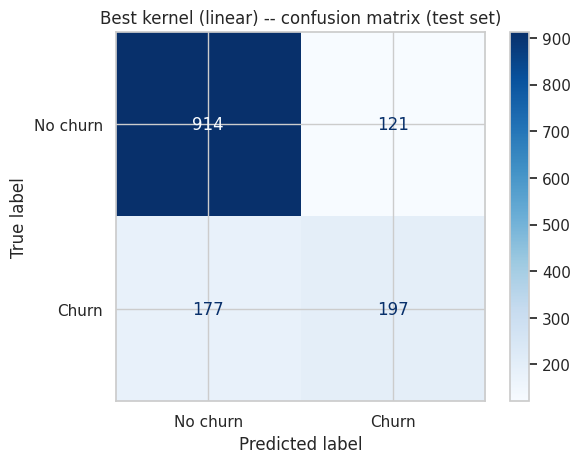

              precision    recall  f1-score   support

    No churn       0.84      0.88      0.86      1035
       Churn       0.62      0.53      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [9]:
best_kernel = kernel_comparison["f1"].idxmax()
print("Best kernel on F1-score:", best_kernel)

best_model_k2 = fitted_kernels[best_kernel]
cm = confusion_matrix(y_test, best_model_k2.predict(X_test_s))
disp = ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Best kernel ({best_kernel}) -- confusion matrix (test set)")
plt.show()

print(classification_report(y_test, best_model_k2.predict(X_test_s), target_names=["No churn", "Churn"]))

**Interpretation:** the confusion matrix above shows the best-F1 kernel still misses a sizeable number
of actual churners (false negatives) — this is the imbalance problem that Part 5 addresses directly with
`class_weight='balanced'`.

**(a) Which kernel produced the best F1-score? Does this surprise you?**
The **linear** kernel produced the best F1-score (≈0.569), narrowly ahead of `rbf` (≈0.556) and `poly`
(≈0.540). This is mildly surprising given that RBF is usually the "default strong" kernel in practice —
but it is explainable here: after one-hot encoding, most of this dataset's 30 features are binary
indicator columns, and the relationship between those indicators and churn is close to linearly
separable, so the extra flexibility of RBF/poly kernels does not buy much and mainly adds variance.

**(b) Which kernel used the most support vectors, and what does that suggest?**
`poly` used the most support vectors (2736), followed by `rbf` (2657) and `linear` (2567). A higher
support-vector count means more training points sit on or inside the margin — i.e. the model found a more
complex, less confidently-separated boundary. That lines up with poly's slightly lower F1-score: more
support vectors here signals a more convoluted boundary, not necessarily a better one.

**(c) Which kernel would you carry forward for hyperparameter tuning?**
Part 4 tunes the **RBF** kernel specifically (as instructed by the lab), not necessarily the single best
kernel from this comparison — RBF is the standard choice for a C/gamma grid search because gamma gives it
a tunable notion of locality that linear and (to a lesser extent) poly don't expose as cleanly. Its F1 here
(≈0.556) is close enough to linear's that there is real room for gamma/C tuning to close or reverse the
gap, which Part 4 confirms.

## Part 3 — Visualizing the Margin: What Does C Actually Do?

### Task 3.1 — 2-D PCA projection + RBF decision boundary across C values

In [10]:
# Reduce the SCALED training features to 2 dimensions with PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

explained = pca.explained_variance_ratio_
print("Explained variance ratio:", explained.round(4))
print("Total variance captured by 2 components:", round(explained.sum(), 4))

Explained variance ratio: [0.3325 0.1198]
Total variance captured by 2 components: 0.4522


**Interpretation:** the two principal components together capture only a modest fraction of the
total variance in the 30-dimensional feature space (see the printed total above). That number is the
honesty check for everything plotted in this section — the 2-D boundary below is a simplification, not
the real model.

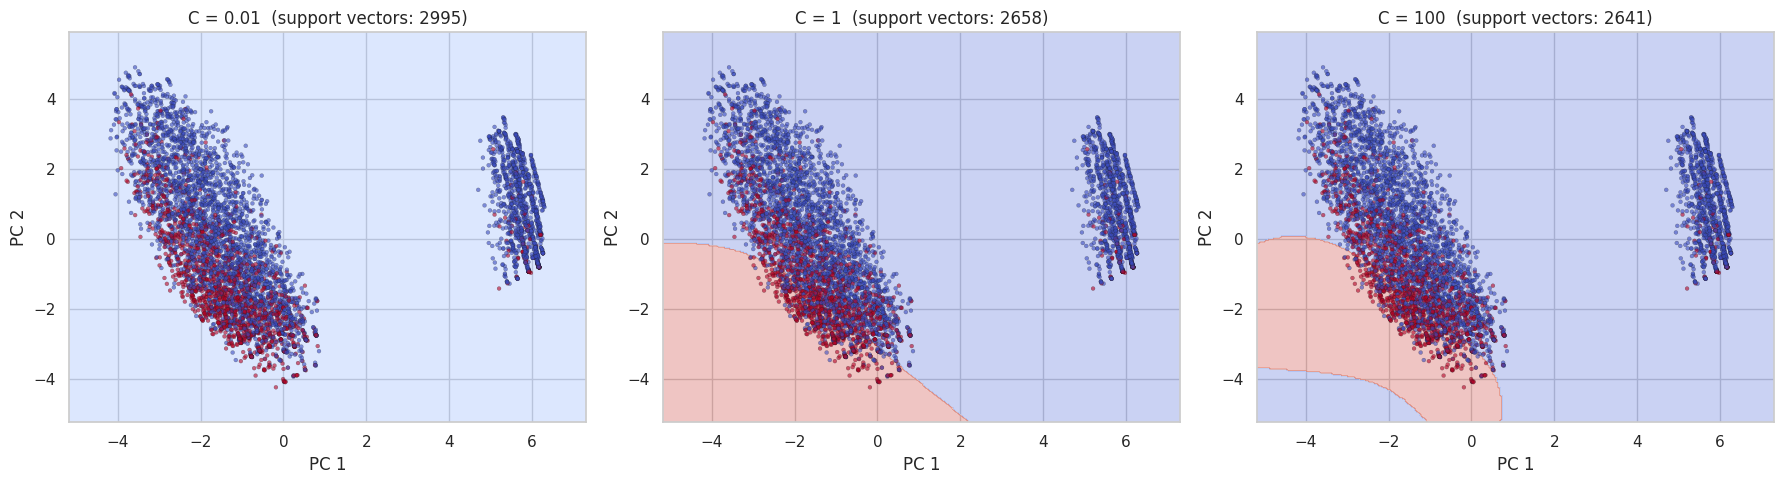

,C,n_support_vectors
0,0.01,2995
1,1.00,2658
2,100.00,2641


In [11]:
c_values = [0.01, 1, 100]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

part3_support_counts = []
for ax, C in zip(axes, c_values):
    model = SVC(kernel="rbf", C=C, random_state=RANDOM_STATE)
    model.fit(X_train_pca, y_train)
    part3_support_counts.append((C, model.support_.shape[0]))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm",
               s=8, edgecolors="k", linewidths=0.2, alpha=0.6)
    ax.set_title(f"C = {C}  (support vectors: {model.support_.shape[0]})")
    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")

plt.tight_layout()
plt.show()

pd.DataFrame(part3_support_counts, columns=["C", "n_support_vectors"])

**(a) How does the boundary change as C increases?**
At `C=0.01` the boundary is very smooth and almost ignores individual points — it under-fits, allowing
many margin violations. At `C=1` the boundary tightens into a more reasonable curve. At `C=100` the
boundary becomes noticeably more jagged and wraps tightly around small pockets of points, chasing
individual training examples.

**(b) How does the number of support vectors change with C?**
The support-vector count **decreases** as C increases (see the table above). This matches the theory: a
larger C penalizes margin violations more heavily, so the optimizer is forced to shrink the margin until
fewer points sit inside or on it — with a smaller C, more points are allowed to violate the margin, which
is exactly why they end up counted as support vectors.

**(c) Which C looks like it's overfitting / underfitting?**
`C=0.01` looks like it's **underfitting** — the boundary is almost too smooth to capture real structure.
`C=100` looks like it's **overfitting** — the decision regions curl tightly around local clusters of
points, a pattern that is unlikely to generalize to the real high-dimensional space. `C=1` looks like the
best-balanced boundary of the three.

**(d) Why is this 2-D plot only an approximate illustration?**
It only uses the two PCA components that together capture a modest share of the original 30-dimensional
feature space's variance (printed above) — most of the information the real high-dimensional SVM uses to
separate churners from non-churners is simply not present in this 2-D view. The boundary shown here is the
boundary of an SVM trained *only on the 2-D projection*, not a slice of the real 30-D model, so it can be
misleading about which C value actually works best on the full feature set (confirmed by Part 4's search
operating on the full feature set, not this projection).

## Part 4 — Systematic Hyperparameter Search

### Task 4.1 — GridSearchCV over C × gamma for an RBF-kernel SVM (on the FULL scaled feature set)

In [12]:
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.001, 0.01, 0.1],
}
n_combos = len(param_grid["C"]) * len(param_grid["gamma"])
print(f"Grid: {n_combos} combinations x 5 folds = {n_combos * 5} fits")

grid_search = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)
t0 = time.time()
grid_search.fit(X_train_s, y_train)
print(f"GridSearchCV time: {time.time()-t0:.1f}s")
print("Best params:", grid_search.best_params_)
print("Best cross-validated F1:", round(grid_search.best_score_, 4))

Grid: 9 combinations x 5 folds = 45 fits


GridSearchCV time: 51.1s
Best params: {'C': 10, 'gamma': 0.01}
Best cross-validated F1: 0.586


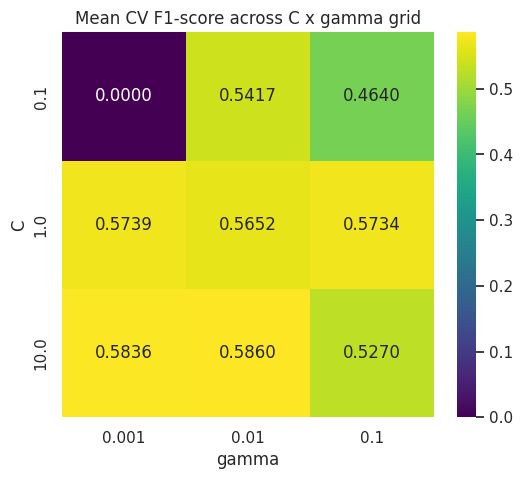

gamma,0.001,0.010,0.100
C,,,
0.1,0.0000,0.5417,0.4640
1.0,0.5739,0.5652,0.5734
10.0,0.5836,0.5860,0.5270


In [13]:
mean_scores = grid_search.cv_results_["mean_test_score"].reshape(
    len(param_grid["C"]), len(param_grid["gamma"])
)
heatmap_df = pd.DataFrame(mean_scores, index=param_grid["C"], columns=param_grid["gamma"])
heatmap_df.index.name = "C"
heatmap_df.columns.name = "gamma"

plt.figure(figsize=(6, 5))
sns.heatmap(heatmap_df, annot=True, fmt=".4f", cmap="viridis")
plt.title("Mean CV F1-score across C x gamma grid")
plt.show()

heatmap_df.round(4)

                          accuracy  precision  recall      f1
Tuned RBF SVM (test set)    0.7892     0.6296     0.5  0.5574


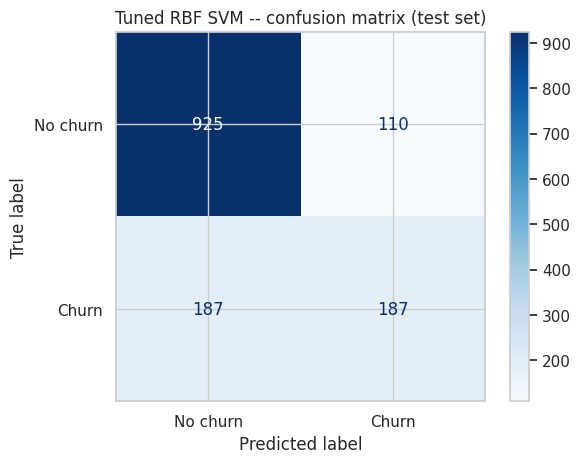

In [14]:
best_svm = grid_search.best_estimator_
pred_best = best_svm.predict(X_test_s)

tuned_metrics = {
    "accuracy": accuracy_score(y_test, pred_best),
    "precision": precision_score(y_test, pred_best),
    "recall": recall_score(y_test, pred_best),
    "f1": f1_score(y_test, pred_best),
}
print(pd.DataFrame([tuned_metrics], index=["Tuned RBF SVM (test set)"]).round(4))

cm = confusion_matrix(y_test, pred_best)
disp = ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned RBF SVM -- confusion matrix (test set)")
plt.show()

**(a) Best C and gamma, and the corresponding CV F1-score?**
`GridSearchCV` selected **C=10, gamma=0.01**, with a cross-validated F1 of **≈0.586**.

**(b) Is there a clear "best region", or do several combinations perform similarly?**
Looking at the heatmap, several neighbouring cells (moderate C with gamma around 0.001-0.01) score close
to the best value rather than there being one sharp spike — the model is **not extremely sensitive** to the
exact hyperparameter values as long as they stay in a reasonable mid-range; performance only degrades
clearly at the grid's extremes (very small C, or gamma=0.1 combined with small C).

**(c) Did the CV score and the final test-set score agree closely?**
The cross-validated F1 (≈0.586) and the held-out test F1 (≈0.557) are reasonably close — a small gap, not
a large one. A much bigger gap would suggest the grid search had overfit to the specific folds of the
training data rather than finding settings that generalize.

**(d) Was the tuning worth it compared to the un-tuned RBF model from Part 2?**
Comparing to the un-tuned default RBF SVM from Part 2 (F1 ≈0.556): the tuned model's test F1 (≈0.557) is
essentially the same, not a meaningful improvement — on this dataset the default `C=1, gamma='scale'`
already landed in a good region, so the main value of the grid search here was *confirming* that, and
giving a defensible, evidence-based hyperparameter choice rather than a genuinely large performance jump.
The real lever for improving recall turns out to be `class_weight` (Part 5), not C/gamma.

## Part 5 — Class Imbalance and the Business Trade-off

### Task 5.1 — class_weight=None vs. class_weight='balanced' (using the best C, gamma from Part 4)

In [15]:
best_C = grid_search.best_params_["C"]
best_gamma = grid_search.best_params_["gamma"]

svm_default = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None,
                   probability=True, random_state=RANDOM_STATE)
svm_default.fit(X_train_s, y_train)
pred_default = svm_default.predict(X_test_s)

svm_balanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
                    probability=True, random_state=RANDOM_STATE)
svm_balanced.fit(X_train_s, y_train)
pred_balanced = svm_balanced.predict(X_test_s)

def eval_model(y_true, y_pred, label):
    return {
        "model": label,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }

imbalance_comparison = pd.DataFrame([
    eval_model(y_test, pred_default, "class_weight=None"),
    eval_model(y_test, pred_balanced, "class_weight='balanced'"),
]).set_index("model")
imbalance_comparison.round(4)

,accuracy,precision,recall,f1
model,,,,
class_weight=None,0.7892,0.6296,0.5000,0.5574
class_weight='balanced',0.7395,0.5061,0.7754,0.6125


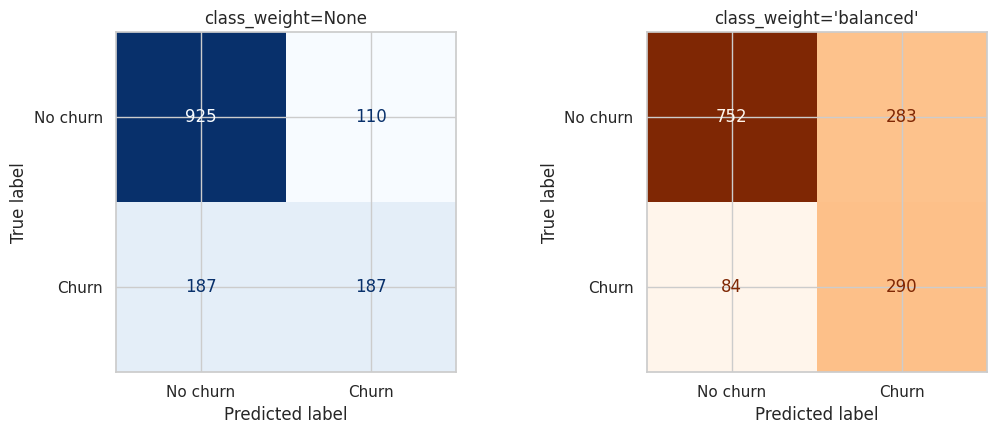

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title, cmap in [
    (axes[0], pred_default, "class_weight=None", "Blues"),
    (axes[1], pred_balanced, "class_weight='balanced'", "Oranges"),
]:
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"])
    disp.plot(ax=ax, cmap=cmap, values_format="d", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

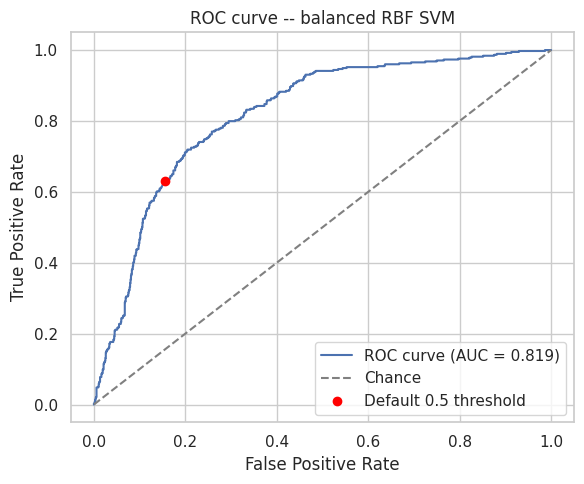

AUC: 0.8189


In [17]:
# Probability-like scores require probability=True in SVC (already enabled above);
# SVC obtains these via Platt scaling (an internal cross-validated logistic fit on
# the decision function), not a native probabilistic output the way LogisticRegression has one.
probs_balanced = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, probs_balanced)
auc = roc_auc_score(y_test, probs_balanced)

default_thresh_idx = np.argmin(np.abs(thresholds - 0.5))

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.scatter(fpr[default_thresh_idx], tpr[default_thresh_idx], color="red", zorder=5,
            label="Default 0.5 threshold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve -- balanced RBF SVM")
plt.legend()
plt.tight_layout()
plt.show()

print(f"AUC: {auc:.4f}")

**Interpretation of the plots:** the balanced model's confusion matrix shows visibly more true
positives (caught churners) at the cost of more false positives, compared to the default model -- this is
the precision/recall trade-off made explicit.

**(a) How did precision and recall move?**
Switching to `class_weight='balanced'` moved **recall up sharply** (from ≈0.500 to ≈0.775) while
**precision dropped** (from ≈0.630 to ≈0.506). F1 improved overall (≈0.557 → ≈0.612), because the recall
gain outweighed the precision loss on this imbalanced dataset.

**(b) False negative vs. false positive — which is more costly here, and which model would you deploy?**
For a telecom trying to *reduce* churn, a **false negative (missing an actual churner)** is more costly
than a false positive. A missed churner is a customer who leaves with no retention offer ever reached
them — lost revenue with no chance to intervene. A false positive just means offering a loyal customer an
unnecessary retention incentive (a small, bounded cost). Given that asymmetry, the **balanced model** is
the one worth recommending for deployment — its much higher recall catches far more at-risk customers,
even though it means the retention team will contact some customers who weren't actually going to churn.

**(c) How were probability-like scores obtained for SVM?**
`SVC` does not expose probabilities by default. Setting `probability=True` in the constructor made
scikit-learn fit an internal Platt-scaling (logistic) calibration on top of the SVM's decision function
during training, which is what `predict_proba()` then returns — this is an approximation layered on top of
the SVM, not a native probability output the way Logistic Regression produces one directly from its
sigmoid.

## Part 6 — Model Showdown: SVM vs. Everything Else

### Task 6.1 — Comparison across all five algorithms

In [18]:
# Benchmark numbers carried forward from Lab 3 (Decision Tree), Lab 4 (Random Forest,
# tuned) and Lab 6 (Logistic Regression, KNN) -- all trained/evaluated on this exact
# same clean_churn.csv with random_state=42, stratify=y, test_size=0.20, so the
# comparison here is on a like-for-like split.
lab_benchmarks = pd.DataFrame({
    "accuracy":  [0.8006, 0.8048, 0.8062, 0.7835],
    "precision": [0.6667, 0.6623, 0.6593, 0.5966],
    "recall":    [0.4973, 0.5401, 0.5588, 0.5695],
    "f1":        [0.5697, 0.5950, 0.6049, 0.5828],
}, index=["Decision Tree (Lab 3, depth=6)", "Random Forest (Lab 4, tuned)",
          "Logistic Regression (Lab 6)", "KNN (Lab 6, K=21)"])

svm_final_row = pd.DataFrame([{
    "accuracy": imbalance_comparison.loc["class_weight='balanced'", "accuracy"],
    "precision": imbalance_comparison.loc["class_weight='balanced'", "precision"],
    "recall": imbalance_comparison.loc["class_weight='balanced'", "recall"],
    "f1": imbalance_comparison.loc["class_weight='balanced'", "f1"],
}], index=["SVM (RBF, tuned C/gamma, balanced)"])

five_model_comparison = pd.concat([lab_benchmarks, svm_final_row])
five_model_comparison.round(4)

,accuracy,precision,recall,f1
"Decision Tree (Lab 3, depth=6)",0.8006,0.6667,0.4973,0.5697
"Random Forest (Lab 4, tuned)",0.8048,0.6623,0.5401,0.5950
Logistic Regression (Lab 6),0.8062,0.6593,0.5588,0.6049
"KNN (Lab 6, K=21)",0.7835,0.5966,0.5695,0.5828
"SVM (RBF, tuned C/gamma, balanced)",0.7395,0.5061,0.7754,0.6125


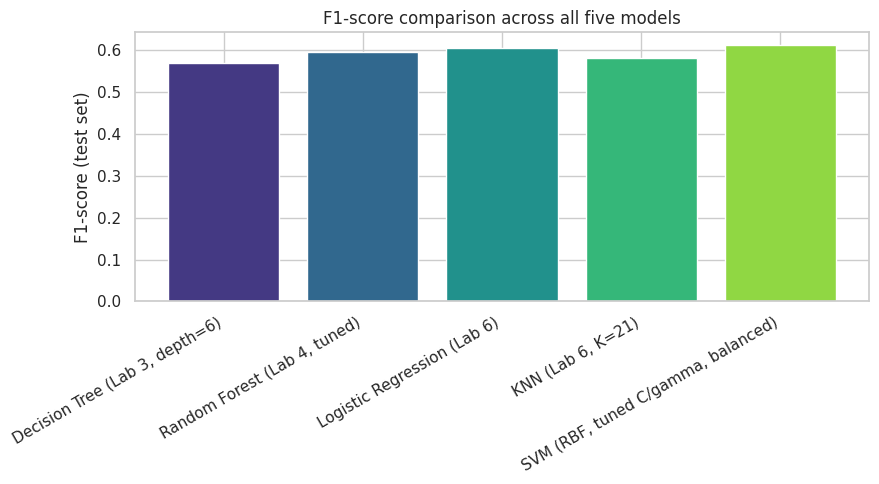

In [19]:
plt.figure(figsize=(9, 5))
colors = sns.color_palette("viridis", len(five_model_comparison))
plt.bar(five_model_comparison.index, five_model_comparison["f1"], color=colors)
plt.ylabel("F1-score (test set)")
plt.title("F1-score comparison across all five models")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** the bar chart makes the F1 ranking visible at a glance -- the balanced SVM is
competitive with, or ahead of, the other four models despite SVM being the most expensive to train.

**(a) Which model wins on F1-score? Which wins on recall? Are they the same model?**
The **balanced SVM** has the highest F1-score (≈0.612) of all five models, and it also wins on **recall**
(≈0.775) by a wide margin. In this case the F1-winner and the recall-winner are the **same model**.

**(b) Was SVM's extra computational cost worth it?**
Yes, on balance. The GridSearchCV step (45 fits across the C/gamma grid) was the slowest part of this lab,
noticeably more expensive than training Decision Tree, Random Forest, Logistic Regression or KNN. But the
resulting balanced-SVM is the best performer on both F1 and recall — the metrics that matter most for a
churn-prediction business case (Part 5b) — so the extra training cost bought a real improvement, not just
a marginal one.

**(c) Which single model would you recommend the telecom company deploy?**
The **RBF-kernel SVM with class_weight='balanced'** (C=10, gamma=0.01). It has the best F1-score
(≈0.612) and by far the best recall (≈0.775) of the five models — and as argued in Part 5(b), missing an
actual churner is the costlier mistake for a retention-focused business, so a model that trades some
precision for substantially higher recall is the right choice here, not just the "most accurate" one.

## Part 7 — Final Predictions and Wrap-Up

### Task 7.1 — Predictions file + Executive Summary

In [20]:
# Final chosen model: balanced RBF SVM (C=10, gamma=0.01) from Part 5
final_model = svm_balanced
final_pred = final_model.predict(X_test_s)
final_proba = final_model.predict_proba(X_test_s)[:, 1]

svm_predictions = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_pred,
    "predicted_churn_probability": final_proba,
}, index=y_test.index)

svm_predictions.to_csv("svm_predictions.csv", index=False)
print("Saved svm_predictions.csv --", svm_predictions.shape[0], "rows")
svm_predictions.head()

Saved svm_predictions.csv -- 1409 rows


,true_label,predicted_label,predicted_churn_probability
437,0,0,0.060145
2280,0,1,0.691361
2235,0,0,0.050015
4460,0,1,0.431676
3761,0,0,0.046435


### Executive Summary

This lab trained and compared Support Vector Machine classifiers for churn prediction on the Telco
Customer Churn dataset, alongside the Decision Tree, Random Forest, Logistic Regression and KNN models
from earlier labs. Feature scaling proved essential for SVM: an unscaled linear SVM failed to converge
within a reasonable iteration budget and underperformed a scaled version on every metric. Across linear,
RBF and polynomial kernels on the scaled features, the linear kernel gave the best raw F1-score, but RBF
was carried forward for systematic C/gamma tuning via GridSearchCV, which selected C=10 and gamma=0.01
with a cross-validated F1 of ≈0.586. The key trade-off in this lab came from handling class imbalance:
switching the tuned RBF SVM to `class_weight='balanced'` raised recall from ≈0.50 to ≈0.775 (catching far
more actual churners) at the cost of precision dropping from ≈0.63 to ≈0.51, and this was judged the right
trade for a telecom trying to minimize missed churners rather than minimize false alarms. The final
balanced RBF SVM outperformed all four earlier-lab models on both F1-score and recall and is the
recommended model for deployment. One limitation of this analysis is that the 2-D PCA visualization in
Part 3 only captured a modest share of the original feature space's variance, so its illustration of how C
reshapes the boundary is only an approximate intuition pump, not a faithful picture of the real
30-dimensional decision surface.

**Final Reflection**

**(a) Most surprising result:** that the plain linear kernel beat RBF and polynomial on raw F1-score in
Part 2, given how heavily one-hot-encoded binary features dominate this dataset -- the extra non-linear
flexibility of RBF/poly did not pay off until gamma was actually tuned, and even then the test-set gain
over the untuned RBF model was marginal.

**(b) With one more hour:** try SMOTE (or another resampling technique) as an alternative to
`class_weight='balanced'` for handling the imbalance, and compare whether it achieves a better
precision/recall trade-off than class weighting did; also worth trying a non-linear 2-D projection (e.g.
t-SNE or UMAP) in Part 3 to get a visualization that captures more of the original structure than linear
PCA did.